# Global Financial Markets Dashboard
## SQL Analysis of Historical Financial Market Data
### Objective

This notebook analyzes historical financial market data stored in a SQLite database. Using SQL queries and Python, it explores trading activity, price behavior, returns, trading volume, and volatility across multiple financial assets.

The goal is to transform raw market data into meaningful business insights that can later be visualized in an interactive Tableau dashboard.

Tools Used

* Python
* SQLite
* SQL
* Pandas
* Matplotlib

### 1. Connect to the SQLite Database

The cleaned market data produced by the ETL pipeline is stored in a SQLite database. This section establishes a connection to the database so SQL queries can be executed directly from Python.

In [48]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
connection = sqlite3.connect("../data/database/market_data.db")

The database connection was successfully established and is ready for analysis.

### 2. Trading Days Analysis

The first step is to verify the completeness of the dataset by counting the number of trading days available for each financial asset.

In [49]:
#amount of trading days for each ticker
query = """
SELECT
    Ticker,
    COUNT(*) AS [Trading Days]
FROM market_data
GROUP BY Ticker;
"""

trading_days_df= pd.read_sql(query, connection)
trading_days_df

,Ticker,Trading Days
0,AAPL,22
1,BTC-USD,31
2,CL=F,22
3,ETH-USD,31
4,EURUSD=X,23
5,GC=F,22
6,MSFT,22
7,NVDA,22
8,^GSPC,22
9,^IXIC,22


Most assets contain a similar number of observations, indicating that the ETL pipeline collected the data consistently. Cryptocurrencies contain additional observations because they trade seven days per week.

### 3. Closing Price Analysis

**Highest and Lowest Closing Prices**

This query identifies the highest and lowest closing prices recorded for each asset during the observation period.

In [50]:

#highest and lowest closing prices for each ticker
query = """
SELECT
    Ticker,
    MAX(Close) AS [Highest Closing Price],
    MIN(Close) AS [Lowest Closing Price]
FROM market_data
GROUP BY Ticker
ORDER BY MAX(Close) DESC;
""" 
closing_price_extremes_df = pd.read_sql(query, connection)
closing_price_extremes_df

,Ticker,Highest Closing Price,Lowest Closing Price
0,BTC-USD,66505.125000,58558.859375
1,^IXIC,26281.609375,25297.619141
2,^GSPC,7575.390137,7354.020020
3,GC=F,4181.899902,3985.600098
4,ETH-USD,1933.209961,1564.816650
5,MSFT,402.290009,352.829987
6,AAPL,333.739990,275.149994
7,NVDA,212.500000,192.529999
8,CL=F,86.910004,68.550003
9,EURUSD=X,1.147026,1.135422


Closing prices vary substantially across asset classes due to differences in price scales. These values should not be interpreted as indicators of investment performance.

**Average Closing Price**

The average closing price provides a summary of the typical market price for each asset over the analysis period.

In [51]:
#average closing price for each ticker
query = """
SELECT
    Ticker,
    AVG(Close) AS [Average Closing Price]
FROM market_data
GROUP BY Ticker
ORDER BY AVG(Close) DESC;
"""
average_closing_price_df = pd.read_sql(query, connection)
average_closing_price_df

,Ticker,Average Closing Price
0,BTC-USD,62813.935736
1,^IXIC,25856.641424
2,^GSPC,7479.044123
3,GC=F,4071.736373
4,ETH-USD,1752.449022
5,MSFT,383.312725
6,AAPL,308.713634
7,NVDA,202.356363
8,CL=F,74.845909
9,EURUSD=X,1.141447


Average prices highlight the differences in nominal price levels across markets but are most meaningful when interpreted within the same asset class.

### 4. Daily Return Analysis

Highest and Lowest Daily Returns

Daily returns measure the percentage change in price from one trading day to the next. This query identifies the largest positive and negative daily movements for each asset.

In [52]:
#highest and lowest daily returns for each ticker
query = """
SELECT
    Ticker,
    MAX([Daily Return]) AS [Highest Daily Return],
    MIN([Daily Return]) AS [Lowest Daily Return]
FROM market_data
GROUP BY Ticker
ORDER BY MAX([Daily Return]) DESC;
"""
daily_return_extremes_df = pd.read_sql(query, connection)
daily_return_extremes_df

,Ticker,Highest Daily Return,Lowest Daily Return
0,ETH-USD,6.541319,-3.537927
1,CL=F,6.038807,-5.207146
2,AAPL,4.933364,-4.262352
3,NVDA,4.580389,-2.402414
4,MSFT,4.429514,-2.740029
5,BTC-USD,4.366306,-2.661694
6,GC=F,1.724095,-2.779940
7,^IXIC,1.507291,-1.423451
8,^GSPC,0.780644,-0.640385
9,EURUSD=X,0.079885,-0.025228


Cryptocurrencies and commodities generally experienced larger one-day price changes than traditional equity indices.

**Average Daily Return**

This query calculates the average daily return for each asset, providing an overall measure of daily performance during the sample period.

In [53]:
#average average daily return for each ticker
query = """
SELECT
    Ticker,
    AVG([Daily Return]) AS [Average Daily Return]
FROM market_data
GROUP BY Ticker
ORDER BY AVG([Daily Return]) DESC;
"""
average_daily_return_df = pd.read_sql(query, connection)
average_daily_return_df

,Ticker,Average Daily Return
0,AAPL,0.469052
1,ETH-USD,0.435046
2,NVDA,0.274441
3,GC=F,0.197969
4,MSFT,0.152865
5,BTC-USD,0.142434
6,^GSPC,0.060483
7,CL=F,0.030917
8,^IXIC,0.023655
9,EURUSD=X,0.005749


Average daily returns were relatively small across all assets, as expected over a short observation period.

### 5. Trading Volume Analysis

**Average Trading Volume**

Trading volume measures market activity. This query calculates the average daily trading volume for each asset.

In [54]:
query = """
SELECT
    Ticker,
    AVG(Volume) AS [Average Trading Volume]
FROM market_data
GROUP BY Ticker
ORDER BY AVG(Volume) DESC;
"""
average_volume_df= pd.read_sql(query, connection)
average_volume_df

,Ticker,Average Trading Volume
0,BTC-USD,2.800468e+10
1,ETH-USD,1.071107e+10
2,^IXIC,9.131141e+09
3,^GSPC,5.247221e+09
4,NVDA,1.311734e+08
5,AAPL,6.208885e+07
6,MSFT,4.257471e+07
7,CL=F,2.319580e+05
8,GC=F,5.015182e+03
9,EURUSD=X,0.000000e+00


Some assets consistently traded with much higher volumes than others, reflecting differences in market participation.

**Highest Trading Volume**

This query identifies the single highest trading volume recorded for each asset.

In [55]:
#highest trading volume for each ticker
query = """
SELECT
    Ticker,
    MAX(Volume) AS [Highest Trading Volume]
FROM market_data
GROUP BY Ticker
ORDER BY MAX(Volume) DESC;
"""
highest_trading_volume_df = pd.read_sql(query, connection)
highest_trading_volume_df

,Ticker,Highest Trading Volume
0,BTC-USD,42644106535
1,ETH-USD,16997487730
2,^IXIC,16594580000
3,^GSPC,9105600000
4,AAPL,261775500
5,MSFT,186201600
6,NVDA,179304100
7,CL=F,445251
8,GC=F,95966
9,EURUSD=X,0


Large spikes in trading volume often coincide with periods of increased market activity or major price movements.

### 6. Best and Worst Trading Days

**Top 10 Best Trading Days**

This query identifies the ten highest daily returns across all assets.

In [56]:
#best trading day based on daily return
query = """
SELECT
    Ticker,
    Date,
    [Daily Return] AS [Best Daily Return]
FROM market_data
ORDER BY [Daily Return] DESC
LIMIT 10;
"""
best_days_df = pd.read_sql(query, connection)   
best_days_df

,Ticker,Date,Best Daily Return
0,ETH-USD,2026-07-14 00:00:00,6.541319
1,CL=F,2026-07-13 00:00:00,6.038807
2,ETH-USD,2026-07-02 00:00:00,5.541092
3,AAPL,2026-07-02 00:00:00,4.933364
4,NVDA,2026-07-08 00:00:00,4.580389
5,NVDA,2026-07-10 00:00:00,4.435647
6,MSFT,2026-06-26 00:00:00,4.429514
7,BTC-USD,2026-07-14 00:00:00,4.366306
8,CL=F,2026-07-17 00:00:00,3.669722
9,ETH-USD,2026-07-03 00:00:00,3.420872


The strongest daily gains were primarily observed in the more volatile asset classes.

**Top 10 Worst Trading Days**

This query identifies the ten largest daily losses across all assets.

In [57]:
#worst trading day based on daily return
query = """
SELECT
    Ticker,
    Date,
    [Daily Return] AS [Worst Daily Return]
FROM market_data
ORDER BY [Daily Return] ASC
LIMIT 10;
"""
worst_days_df = pd.read_sql(query, connection)
worst_days_df

,Ticker,Date,Worst Daily Return
0,CL=F,2026-06-22 00:00:00,-5.207146
1,AAPL,2026-06-25 00:00:00,-4.262352
2,CL=F,2026-07-09 00:00:00,-3.829213
3,CL=F,2026-06-24 00:00:00,-3.815125
4,ETH-USD,2026-06-23 00:00:00,-3.537927
5,ETH-USD,2026-06-25 00:00:00,-3.399545
6,CL=F,2026-06-26 00:00:00,-3.093504
7,ETH-USD,2026-07-16 00:00:00,-2.805707
8,GC=F,2026-06-24 00:00:00,-2.779940
9,MSFT,2026-06-25 00:00:00,-2.740029


Large negative returns were concentrated in the same assets that exhibited the greatest volatility.

**Best and Worst Day for Each Asset**

This query combines each asset’s best and worst trading day into a single table for easier comparison.

In [58]:
#best and worst trading days based on daily return for each ticker
query = """
SELECT
    Ticker,
    Date,
    [Daily Return],
    'Best' AS Return_Type
FROM market_data
WHERE (Ticker, [Daily Return]) IN (
    SELECT
        Ticker,
        MAX([Daily Return])
    FROM market_data
    GROUP BY Ticker
)

UNION ALL

SELECT
    Ticker,
    Date,
    [Daily Return],
    'Worst' AS Return_Type
FROM market_data
WHERE (Ticker, [Daily Return]) IN (
    SELECT
        Ticker,
        MIN([Daily Return])
    FROM market_data
    GROUP BY Ticker
)

ORDER BY Ticker, Return_Type;
"""
closing_price_extremes_df = pd.read_sql(query, connection)
closing_price_extremes_df

,Ticker,Date,Daily Return,Return_Type
0,AAPL,2026-07-02 00:00:00,4.933364,Best
1,AAPL,2026-06-25 00:00:00,-4.262352,Worst
2,BTC-USD,2026-07-14 00:00:00,4.366306,Best
3,BTC-USD,2026-06-24 00:00:00,-2.661694,Worst
4,CL=F,2026-07-13 00:00:00,6.038807,Best
5,CL=F,2026-06-22 00:00:00,-5.207146,Worst
6,ETH-USD,2026-07-14 00:00:00,6.541319,Best
7,ETH-USD,2026-06-23 00:00:00,-3.537927,Worst
8,EURUSD=X,2026-07-22 00:00:00,0.079885,Best
9,EURUSD=X,2026-07-16 00:00:00,-0.025228,Worst


Each asset experienced periods of both exceptional gains and significant losses, illustrating the variability of financial markets.

### 7. Volatility Analysis

Unlike the previous analyses, volatility is calculated using pandas because SQLite does not provide a built-in standard deviation function. Volatility is measured as the standard deviation of daily returns.

In [59]:
market_data = pd.read_sql(
    "SELECT * FROM market_data",
    connection
)
volatility_df = (
    market_data
    .groupby("Ticker")["Daily Return"]
    .std()
    .reset_index()
)
volatility_df.columns = [
    "Ticker",
    "Volatility"
]
volatility_df

,Ticker,Volatility
0,AAPL,2.067765
1,BTC-USD,1.681767
2,CL=F,2.735412
3,ETH-USD,2.380901
4,EURUSD=X,0.021073
5,GC=F,1.241960
6,MSFT,1.856255
7,NVDA,1.867055
8,^GSPC,0.406854
9,^IXIC,0.814754


Higher volatility indicates greater day-to-day price fluctuations and therefore higher investment risk.

### 8. Visualizations

The following charts summarize the most important results obtained from the SQL analysis and provide an intuitive comparison across financial assets.

#### Figure 1 – Trading Days by Asset

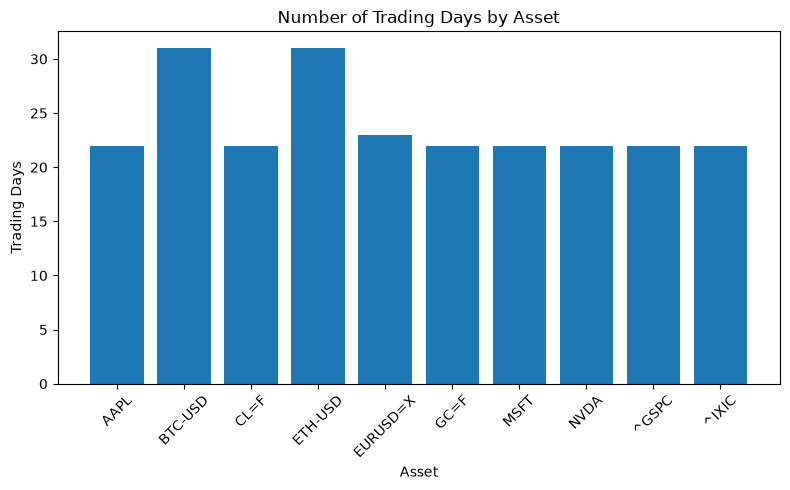

In [60]:
plt.figure(figsize=(8,5))

plt.bar(
    trading_days_df["Ticker"],
    trading_days_df["Trading Days"]
)

plt.title("Number of Trading Days by Asset")
plt.xlabel("Asset")
plt.ylabel("Trading Days")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../assets/figures/trading_days.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The dataset contains a consistent number of observations for most assets.

#### Figure 2 – Average Closing Price

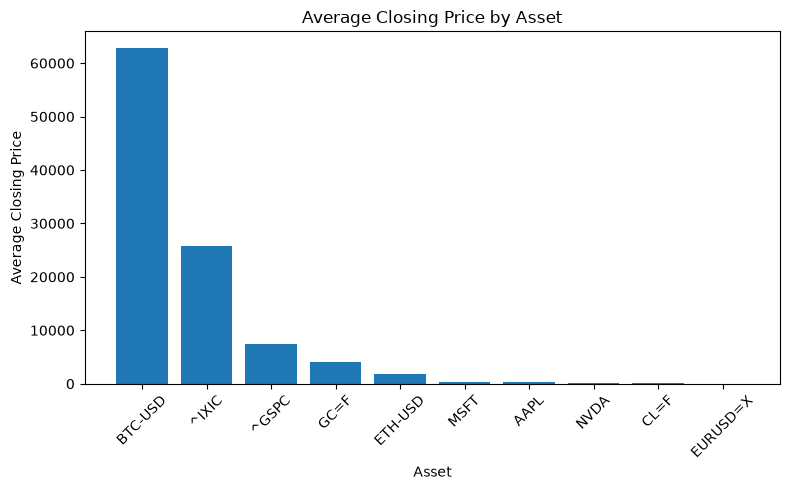

In [61]:
plt.figure(figsize=(8,5))

plt.bar(
    average_closing_price_df["Ticker"],
    average_closing_price_df["Average Closing Price"]
)

plt.title("Average Closing Price by Asset")
plt.xlabel("Asset")
plt.ylabel("Average Closing Price")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../assets/figures/average_closing_price.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Nominal price levels differ substantially between asset classes.

#### Figure 3 – Average Daily Return

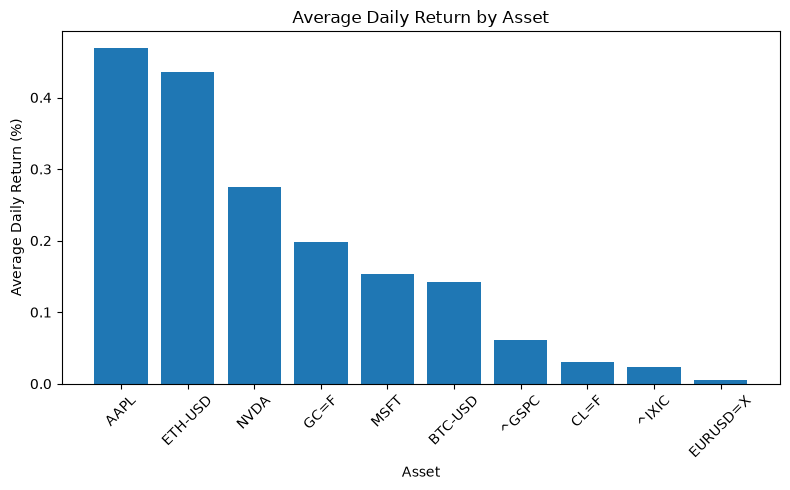

In [62]:
plt.figure(figsize=(8,5))

plt.bar(
    average_daily_return_df["Ticker"],
    average_daily_return_df["Average Daily Return"]
)

plt.title("Average Daily Return by Asset")
plt.xlabel("Asset")
plt.ylabel("Average Daily Return (%)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../assets/figures/average_daily_return.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Average daily returns remain relatively small despite occasional large daily movements.

#### Figure 4 – Average Trading Volume

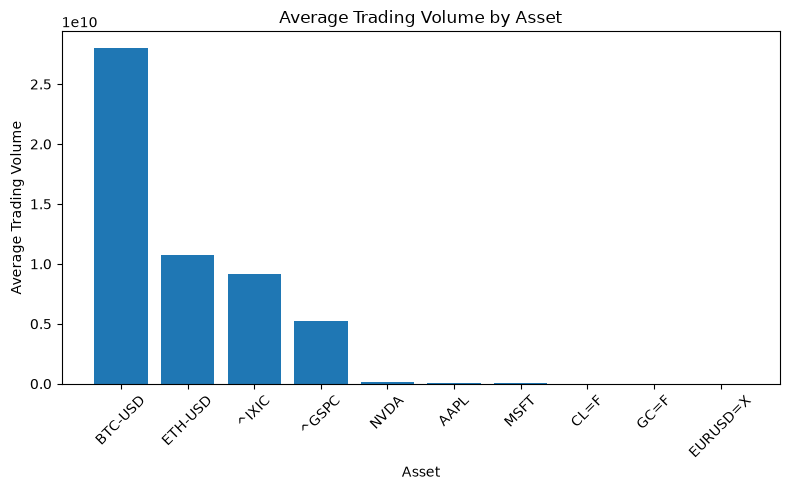

In [63]:
plt.figure(figsize=(8,5))

plt.bar(
    average_volume_df["Ticker"],
    average_volume_df["Average Trading Volume"]
)

plt.title("Average Trading Volume by Asset")
plt.xlabel("Asset")
plt.ylabel("Average Trading Volume")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../assets/figures/average_trading_volume.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Trading activity varies considerably between markets.

#### Figure 5 – Volatility

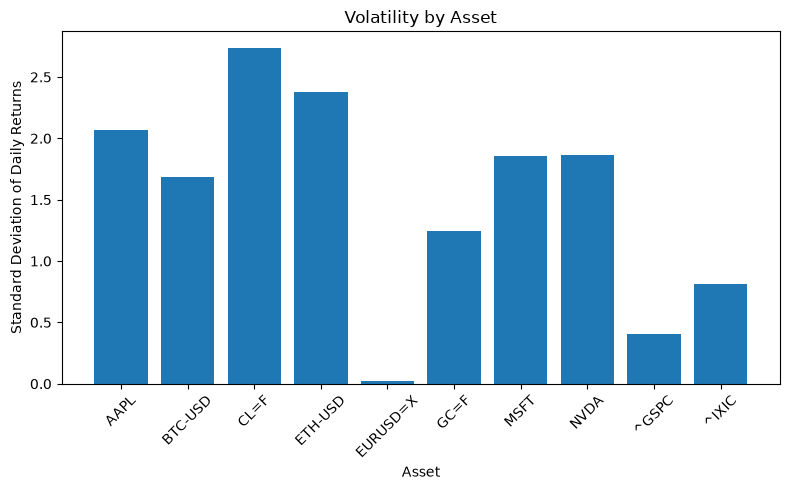

In [64]:
plt.figure(figsize=(8,5))

plt.bar(
    volatility_df["Ticker"],
    volatility_df["Volatility"]
)

plt.title("Volatility by Asset")
plt.xlabel("Asset")
plt.ylabel("Standard Deviation of Daily Returns")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../assets/figures/volatility.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

More volatile assets display larger day-to-day price fluctuations.

### 9. Key Findings

This analysis explored historical market data for equities, cryptocurrencies, commodities, stock indices, and foreign exchange using SQL and Python.

The main findings are:

* The ETL pipeline successfully collected and stored a consistent dataset for all analyzed assets in SQLite.
* Cryptocurrencies contained more observations because they trade every day, while stocks, indices, and commodities follow market trading calendars.
* Bitcoin had the highest nominal closing price in the dataset, although nominal prices are not directly comparable across different asset classes.
* Apple (AAPL) recorded the highest average daily return, while Ethereum and Crude Oil experienced the largest single-day gain and loss, respectively.
* Bitcoin and Ethereum exhibited the highest trading activity based on average trading volume.
* Crude Oil was the most volatile asset during the analysis period, whereas the S&P 500, NASDAQ, and EUR/USD showed comparatively lower volatility.



### 10. Overall Conclusion

This notebook demonstrated how SQL and Python can be combined to analyze historical financial market data stored in SQLite. Using SQL aggregation functions together with pandas and Matplotlib, key characteristics of different asset classes—including prices, returns, trading activity, and volatility—were successfully explored.

The insights obtained in this analysis provide the foundation for the final stage of the project: building an interactive Tableau dashboard that enables users to explore market performance through dynamic visualizations.

In [66]:
connection.close()

The SQL analysis is now complete. The next stage of the project focuses on creating an interactive Tableau dashboard using the processed data.